# Proyek Machine Learning: Prediksi Harga RAM per GB

**Pertanyaan Penelitian:**  
> *"Seberapa baik spesifikasi RAM dan indikator pasokan dapat memprediksi harga per GB?"*

---

### Ringkasan Eksekutif
Dalam lanskap teknologi komputasi modern, harga memori (RAM) mengalami volatilitas signifikan akibat dinamika pasokan semikonduktor, utilisasi pabrik (fab utilization), serta lonjakan permintaan chip akselerator AI/HBM. 

Notebook ini mengimplementasikan alur kerja Machine Learning end-to-end untuk memprediksi `price_per_gb` secara objektif menggunakan:
1. **Pemeriksaan & Pembersihan Data**: verifikasi integritas data, konsistensi matematis, dan penanganan tanggal masa depan.
2. **Exploratory Data Analysis (EDA)**: eksplorasi distribusi target, pengaruh generasi RAM, korelasi fitur pasokan dan spesifikasi teknis.
3. **Pencegahan Data Leakage**: evaluasi ketat terhadap fitur target-derived (`price_usd`, `bandwidth_per_dollar`, `price_status`), serta penerapan **chronological train/test split**.
4. **Pipeline Scikit-Learn**: ColumnTransformer dengan imputasi median (numerik), modus (kategorikal), dan One-Hot Encoding.
5. **Benchmarking 4 Model**: DummyRegressor (Baseline), LinearRegression, Ridge, dan RandomForestRegressor.
6. **Evaluasi Objektif & Penyimpanan Model**: analisis residual, feature importance, dan serialisasi pipeline terbaik ke `models/best_model.joblib`.


## 1. Import Library dan Konfigurasi Lingkungan

In [1]:
import os
import sys
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Konfigurasi plot dan warning
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Python version: 3.12.10
Pandas version: 3.0.6
NumPy version: 2.5.3


## 2. Pemuatan dan Pemeriksaan Dataset

Memuat dataset menggunakan path relatif yang aman. Dataset berisi data pasar memori dengan spesifikasi teknis dan indikator rantai pasok global.

In [2]:
# Path relatif yang aman
data_candidates = [
    os.path.join("..", "data", "ram_dataset.csv"),
    os.path.join("data", "ram_dataset.csv"),
    os.path.join("..", "..", "Ultimate_Memory_Shortage_Crisis_Dataset_10k.csv"),
    os.path.join("..", "Ultimate_Memory_Shortage_Crisis_Dataset_10k.csv"),
]

data_path = None
for p in data_candidates:
    if os.path.isfile(p):
        data_path = p
        break

if data_path is None:
    raise FileNotFoundError("Dataset CSV tidak ditemukan pada path yang disediakan.")

print(f"Memuat dataset dari: {os.path.abspath(data_path)}")
df = pd.read_csv(data_path)
print(f"Dimensi dataset: {df.shape[0]} baris x {df.shape[1]} kolom")
df.head(5)


Memuat dataset dari: c:\Ridho file\hardware\ram-price-prediction\data\ram_dataset.csv
Dimensi dataset: 10000 baris x 28 kolom


,kit_id,brand,model_name,timestamp,region,generation,form_factor,capacity_gb,module_count,is_ecc,...,latency_value_index,speed_premium_ratio,price_per_gb,price_usd,market_segment,recommended_usage,price_status,global_inventory_weeks,fab_utilization_rate,gpu_hbm_trend_gb
0,MPN-000000,Mushkin,Mushkin DDR5 6400MT/s,2026-05-13,EMEA,DDR5,DIMM,512,2,False,...,415610.03,8.8352,61.85,31665.53,Enterprise/AI,AI / Data Science,Shortage-Inflated,5.98,0.8543,236.85
1,MPN-000001,Patriot,Patriot DDR6 (Preview) 16000MT/s,2025-09-15,Greater China,DDR6 (Preview),DIMM,32,4,False,...,32041.53,3.4058,95.36,3051.57,Consumer,Gaming (AAA),Shortage-Inflated,7.82,0.7558,182.11
2,MPN-000002,Lexar,Lexar DDR6 (Preview) 12800MT/s,2024-08-27,Latin America,DDR6 (Preview),DIMM,128,2,False,...,66116.65,1.9678,55.10,7052.44,Enterprise/AI,AI / Data Science,Normal,12.18,0.5981,94.52
3,MPN-000003,Lexar,Lexar DDR4 4400MT/s,2024-09-30,EMEA,DDR4,DIMM,128,1,False,...,6188.60,1.9553,6.26,800.88,Enterprise/AI,AI / Data Science,Normal,12.64,0.6121,102.27
4,MPN-000004,Lexar,Lexar DDR5 5600MT/s,2026-07-12,EMEA,DDR5,SODIMM,48,2,False,...,19395.30,5.0509,35.36,1697.09,Consumer,Content Creation,Shortage-Inflated,5.35,0.8790,250.54


### 2.1 Pemeriksaan Tipe Data, Missing Value, dan Duplikasi

In [3]:
# Informasi kolom dan tipe data
print("=== RINGKASAN TIPE DATA ===")
print(df.dtypes.value_counts())

# Pemeriksaan nilai kosong (Missing Values)
null_counts = df.isnull().sum()
print(f"\nTotal kolom dengan missing values: {(null_counts > 0).sum()}")

# Pemeriksaan baris duplikat
dup_count = df.duplicated().sum()
print(f"Total baris duplikat identik: {dup_count}")

# Ringkasan statistik deskriptif numerik
df.describe().T[['mean', 'std', 'min', '50%', 'max']]


=== RINGKASAN TIPE DATA ===


str        13
float64    10
int64       4
bool        1
Name: count, dtype: int64

Total kolom dengan missing values: 0


Total baris duplikat identik: 0


,mean,std,min,50%,max
capacity_gb,122.065600,132.709958,8.0000,64.0000,512.0000
module_count,2.540900,1.561785,1.0000,2.0000,8.0000
speed_mts,6212.941300,2985.474922,2133.0000,6000.0000,21000.0000
cas_latency,32.283700,12.108141,14.0000,32.0000,84.0000
voltage,1.308840,0.118251,1.0000,1.3500,1.4500
true_latency_ns,11.019142,2.708130,5.7143,10.6250,20.6282
bandwidth_per_dollar,85.039791,149.494946,1.0045,27.5960,1395.8613
latency_value_index,49676.586340,82860.285680,161.4300,18083.5050,985954.5000
speed_premium_ratio,4.421987,2.848333,0.9602,3.7883,11.3059
price_per_gb,31.749948,34.253978,3.0900,21.2250,310.4100


### 2.2 Verifikasi Konsistensi Target (`price_per_gb` vs `price_usd / capacity_gb`)
Secara definisi ekonomi, harga per gigabyte harus setara dengan `price_usd / capacity_gb`. Mari kita uji konsistensi nilai ini pada seluruh baris.

In [4]:
calc_ppg = df['price_usd'] / df['capacity_gb']
diff = (df['price_per_gb'] - calc_ppg).abs()

print(f"Selisih maksimum price_per_gb vs (price_usd / capacity_gb): {diff.max():.6f}")
print(f"Rata-rata selisih: {diff.mean():.6f}")
print(f"Jumlah baris dengan deviasi > $0.01: {(diff > 0.01).sum()}")
assert (diff > 0.01).sum() == 0, "Ditemukan inkonsistensi matematis pada target!"
print("Status: KONSISTEN. Hubungan price_per_gb dan price_usd valid.")


Selisih maksimum price_per_gb vs (price_usd / capacity_gb): 0.005000
Rata-rata selisih: 0.002517
Jumlah baris dengan deviasi > $0.01: 0
Status: KONSISTEN. Hubungan price_per_gb dan price_usd valid.


### 2.3 Pemeriksaan Rentang Tanggal & Penanganan Observasi Masa Depan
Proyek ini menguji performa model dengan referensi tanggal saat ini (**19 Oktober 2026**). 
Data observasi setelah tanggal tersebut diperiksa dan didokumentasikan agar tidak menimbulkan asumsi historis yang bias.

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
min_date = df['timestamp'].min()
max_date = df['timestamp'].max()

today_cutoff = pd.Timestamp('2026-10-19')
future_mask = df['timestamp'] > today_cutoff
future_count = future_mask.sum()

print(f"Rentang waktu dataset : {min_date.date()} s.d. {max_date.date()}")
print(f"Tanggal patokan (Hari ini) : {today_cutoff.date()}")
print(f"Jumlah baris setelah {today_cutoff.date()} : {future_count} baris ({future_count/len(df)*100:.2f}%)")

if future_count > 0:
    print(f"Rentang data proyeksi/masa depan: {df.loc[future_mask, 'timestamp'].min().date()} s.d. {df.loc[future_mask, 'timestamp'].max().date()}")
    print("\nDOKUMENTASI PENANGANAN:")
    print("Baris-baris ini TIDAK DIHAPUS agar struktur dataset asli tetap utuh.")
    print("Dengan pembagian kronologis (80% train / 20% test), baris setelah Oktober 2026")
    print("secara alami jatuh ke dalam TEST SET (data uji terbaru), sehingga merepresentasikan")
    print("uji generalisasi masa depan (future out-of-time forecasting) yang realistis.")


Rentang waktu dataset : 2024-01-01 s.d. 2027-01-01
Tanggal patokan (Hari ini) : 2026-10-19
Jumlah baris setelah 2026-10-19 : 682 baris (6.82%)
Rentang data proyeksi/masa depan: 2026-10-20 s.d. 2027-01-01

DOKUMENTASI PENANGANAN:
Baris-baris ini TIDAK DIHAPUS agar struktur dataset asli tetap utuh.
Dengan pembagian kronologis (80% train / 20% test), baris setelah Oktober 2026
secara alami jatuh ke dalam TEST SET (data uji terbaru), sehingga merepresentasikan
uji generalisasi masa depan (future out-of-time forecasting) yang realistis.


## 3. Exploratory Data Analysis (EDA)

Analisis visual untuk memahami pola distribusi target, pengaruh generasi memori, serta interaksi indikator pasokan.

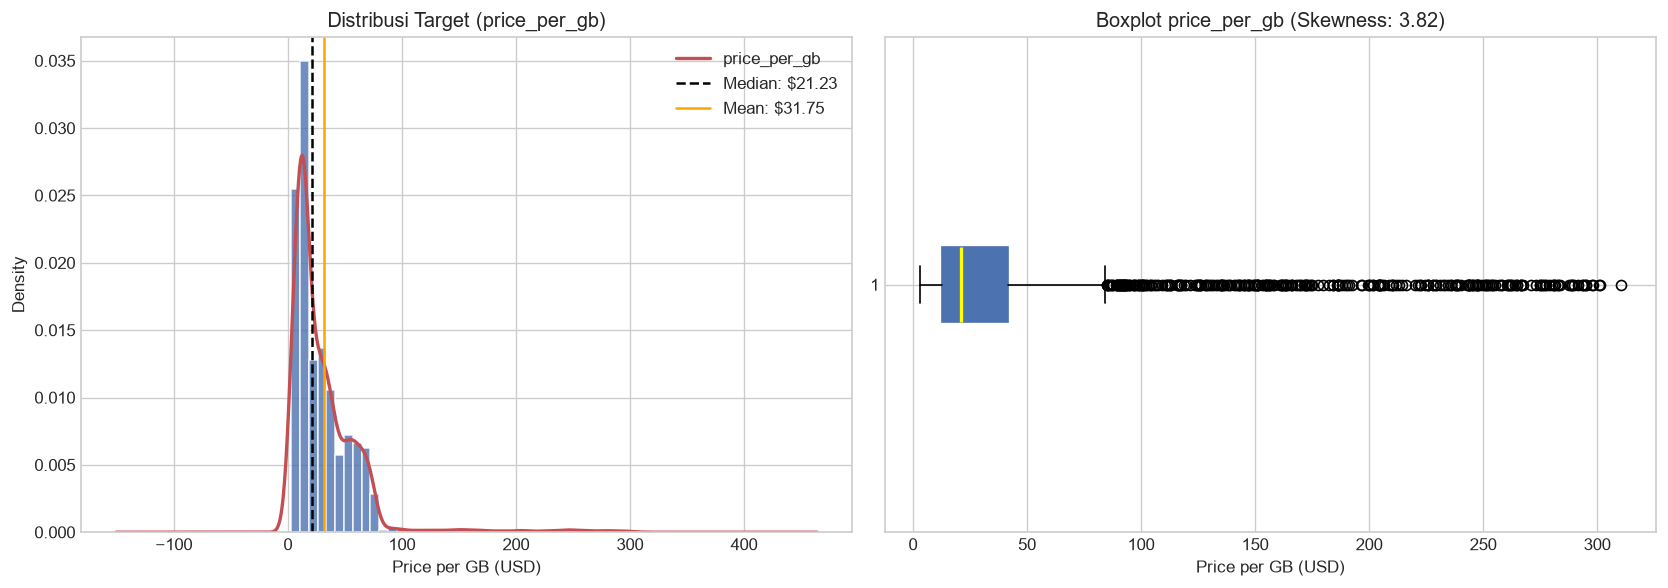

Statistik price_per_gb:
  Min   : $3.09
  25%   : $12.91
  50%   : $21.23
  75%   : $41.67
  Max   : $310.41


In [6]:
# 3.1 Distribusi Target (price_per_gb)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram & KDE
axes[0].hist(df['price_per_gb'], bins=40, color='#4C72B0', edgecolor='white', alpha=0.8, density=True)
df['price_per_gb'].plot(kind='kde', ax=axes[0], color='#C44E52', linewidth=2)
axes[0].axvline(df['price_per_gb'].median(), color='black', linestyle='--', label=f"Median: ${df['price_per_gb'].median():.2f}")
axes[0].axvline(df['price_per_gb'].mean(), color='orange', linestyle='-', label=f"Mean: ${df['price_per_gb'].mean():.2f}")
axes[0].set_title("Distribusi Target (price_per_gb)")
axes[0].set_xlabel("Price per GB (USD)")
axes[0].set_ylabel("Density")
axes[0].legend()

# Boxplot
axes[1].boxplot(df['price_per_gb'], vert=False, patch_artist=True,
                boxprops=dict(facecolor='#4C72B0', color='#4C72B0'),
                medianprops=dict(color='yellow', linewidth=2))
axes[1].set_title(f"Boxplot price_per_gb (Skewness: {df['price_per_gb'].skew():.2f})")
axes[1].set_xlabel("Price per GB (USD)")

plt.tight_layout()
plt.show()

print(f"Statistik price_per_gb:")
print(f"  Min   : ${df['price_per_gb'].min():.2f}")
print(f"  25%   : ${df['price_per_gb'].quantile(0.25):.2f}")
print(f"  50%   : ${df['price_per_gb'].median():.2f}")
print(f"  75%   : ${df['price_per_gb'].quantile(0.75):.2f}")
print(f"  Max   : ${df['price_per_gb'].max():.2f}")


### 3.2 Perbandingan Harga per GB Berdasarkan Generasi RAM

       generation  count   median        mean        std
0            DDR4   2505   10.780   12.773453   8.478150
1            DDR5   7035   27.440   31.872826  20.282704
2  DDR6 (Preview)    460  114.505  133.210109  81.127633


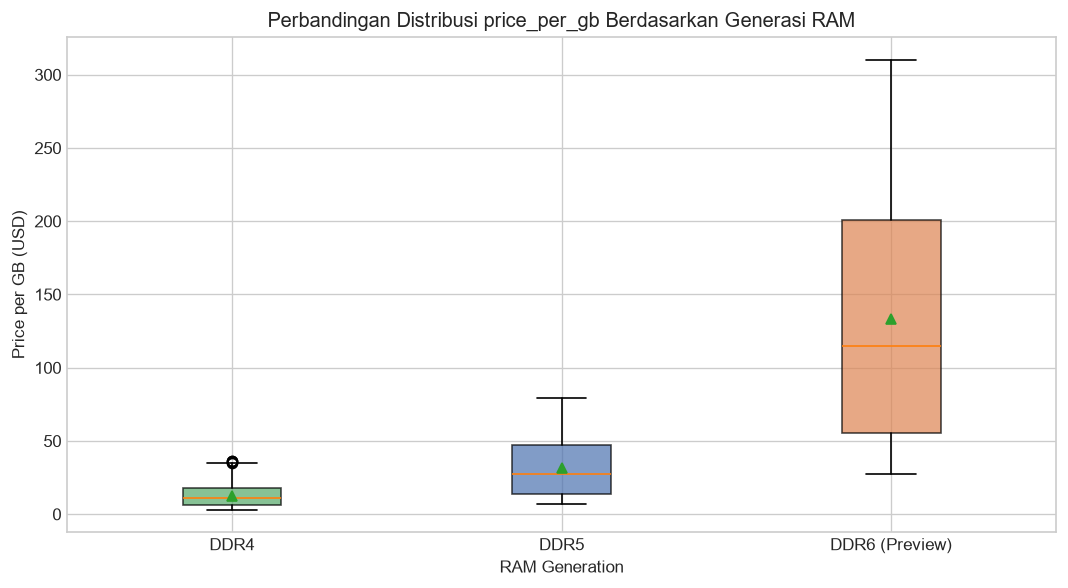

In [7]:
gen_stats = df.groupby('generation')['price_per_gb'].agg(['count', 'median', 'mean', 'std']).reset_index()
print(gen_stats)

fig, ax = plt.subplots(figsize=(9, 5))
gen_order = ['DDR4', 'DDR5', 'DDR6 (Preview)']
box_data = [df[df['generation'] == g]['price_per_gb'].values for g in gen_order]

bp = ax.boxplot(box_data, patch_artist=True, showmeans=True)
ax.set_xticks(range(1, len(gen_order) + 1))
ax.set_xticklabels(gen_order)
colors = ['#55A868', '#4C72B0', '#DD8452']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Perbandingan Distribusi price_per_gb Berdasarkan Generasi RAM")
ax.set_ylabel("Price per GB (USD)")
ax.set_xlabel("RAM Generation")
plt.tight_layout()
plt.show()


### 3.3 Hubungan Kapasitas & Kecepatan dengan Harga per GB

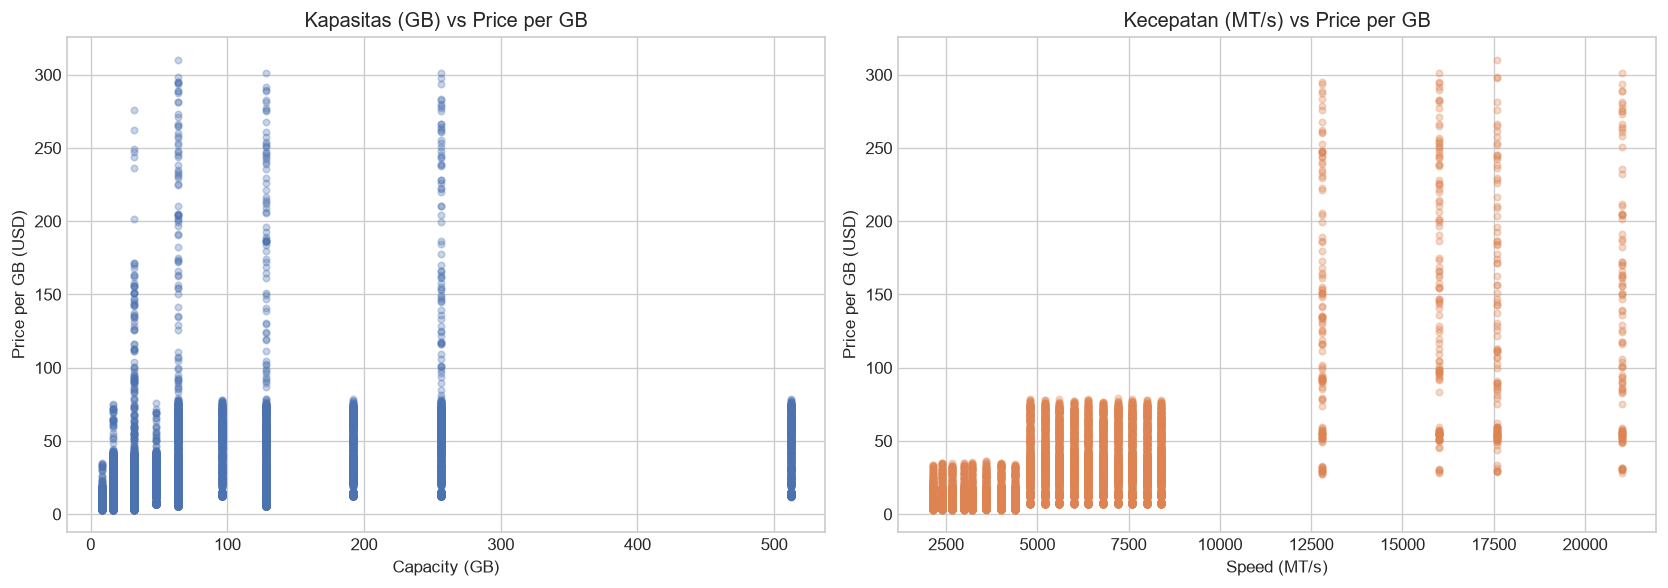

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Kapasitas vs Price per GB
axes[0].scatter(df['capacity_gb'], df['price_per_gb'], alpha=0.3, s=15, color='#4C72B0')
axes[0].set_title("Kapasitas (GB) vs Price per GB")
axes[0].set_xlabel("Capacity (GB)")
axes[0].set_ylabel("Price per GB (USD)")

# Kecepatan vs Price per GB
axes[1].scatter(df['speed_mts'], df['price_per_gb'], alpha=0.3, s=15, color='#DD8452')
axes[1].set_title("Kecepatan (MT/s) vs Price per GB")
axes[1].set_xlabel("Speed (MT/s)")
axes[1].set_ylabel("Price per GB (USD)")

plt.tight_layout()
plt.show()


### 3.4 Hubungan Indikator Pasokan Global dengan Harga per GB

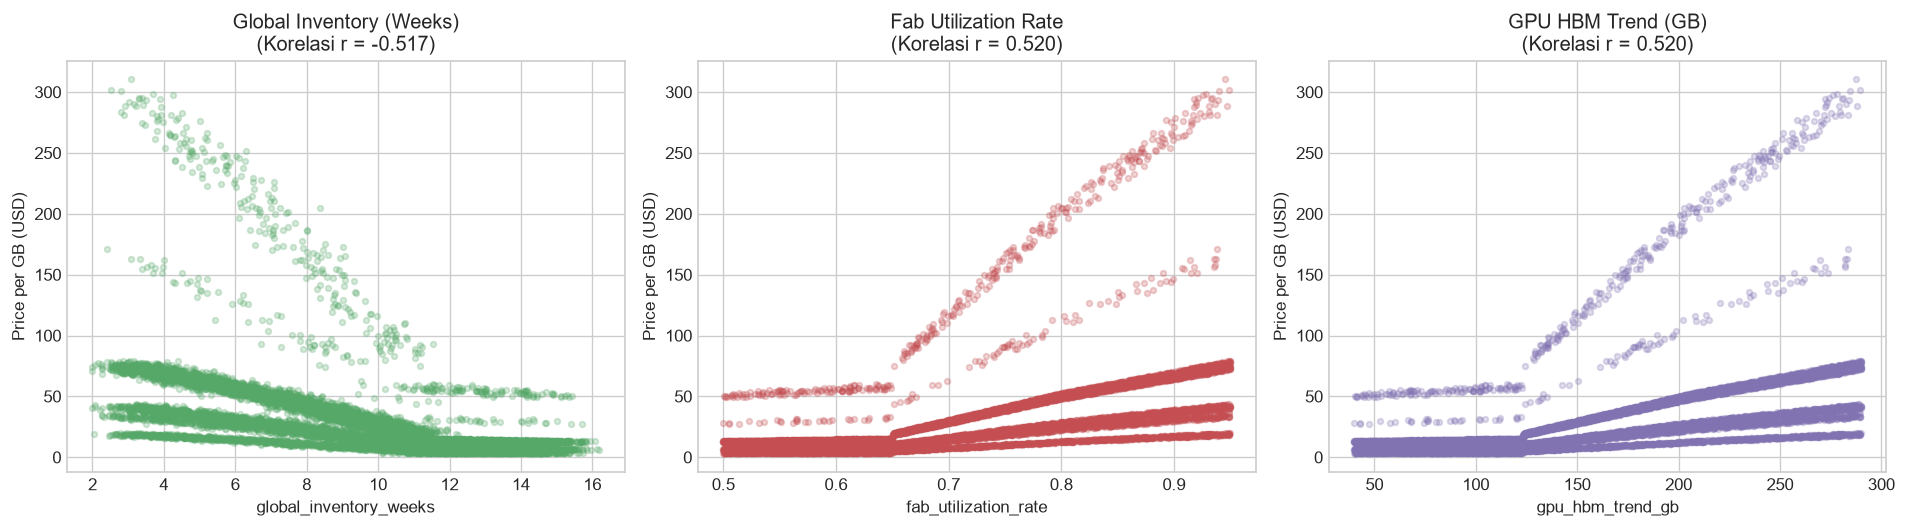

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

supply_cols = [
    ('global_inventory_weeks', 'Global Inventory (Weeks)', '#55A868'),
    ('fab_utilization_rate', 'Fab Utilization Rate', '#C44E52'),
    ('gpu_hbm_trend_gb', 'GPU HBM Trend (GB)', '#8172B2')
]

for ax, (col, title, color) in zip(axes, supply_cols):
    ax.scatter(df[col], df['price_per_gb'], alpha=0.25, s=12, color=color)
    corr = df[col].corr(df['price_per_gb'])
    ax.set_title(f"{title}\n(Korelasi r = {corr:.3f})")
    ax.set_xlabel(col)
    ax.set_ylabel("Price per GB (USD)")

plt.tight_layout()
plt.show()


### 3.5 Matriks Korelasi Fitur Numerik Relevan

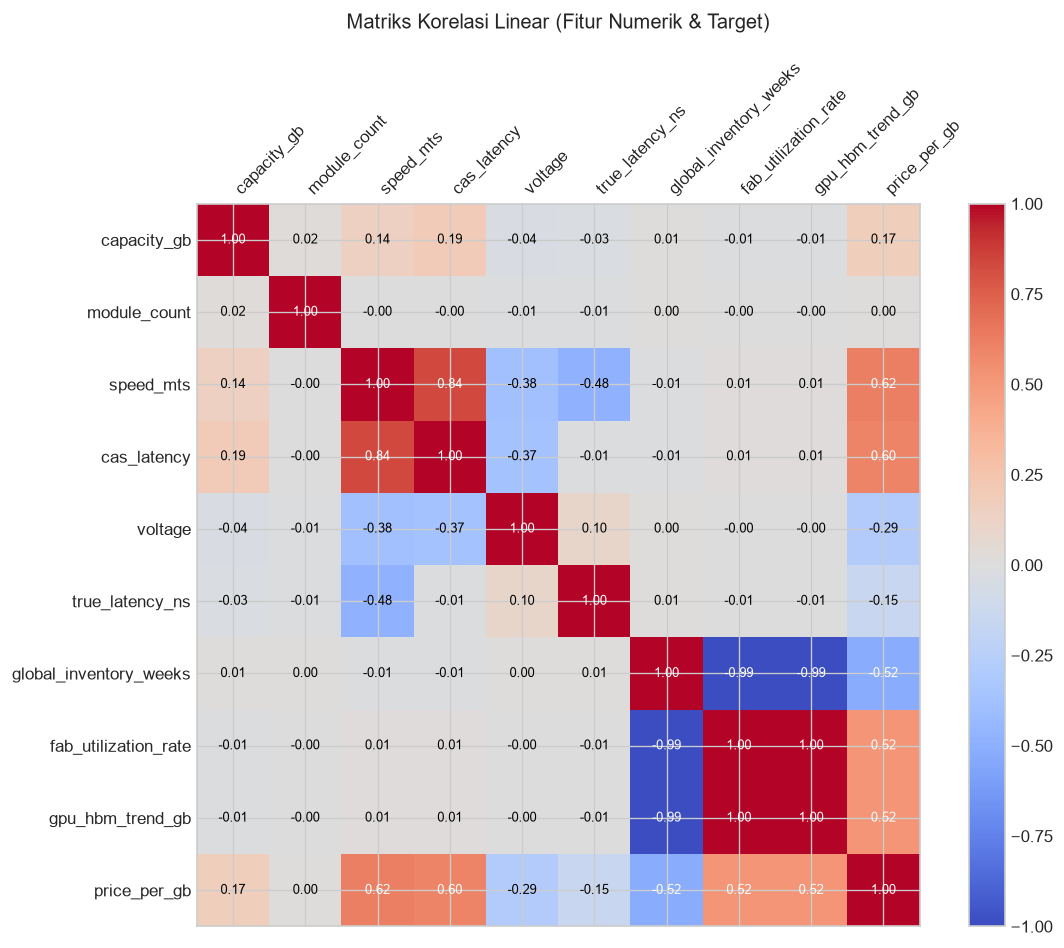

In [10]:
num_cols = [
    'capacity_gb', 'module_count', 'speed_mts', 'cas_latency',
    'voltage', 'true_latency_ns', 'global_inventory_weeks',
    'fab_utilization_rate', 'gpu_hbm_trend_gb', 'price_per_gb'
]

corr_matrix = df[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.matshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

ticks = range(len(num_cols))
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.set_xticklabels(num_cols, rotation=45, ha='left')
ax.set_yticklabels(num_cols)

for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        val = corr_matrix.iloc[i, j]
        ax.text(j, i, f"{val:.2f}", ha='center', va='center',
                color='white' if abs(val) > 0.5 else 'black', fontsize=8)

ax.set_title("Matriks Korelasi Linear (Fitur Numerik & Target)\n", fontsize=12)
plt.tight_layout()
plt.show()


## 4. Strategi Fitur dan Pencegahan Data Leakage

### 4.1 Fitur yang Digunakan vs Dikeluarkan
Untuk memastikan model dapat digunakan secara praktis pada saat inferensi dan tidak mengalami **data leakage**:

| Kategori | Kolom | Status | Alasan |
|---|---|---|---|
| **Target** | `price_per_gb` | **Target** | Nilai yang diprediksi |
| **Leakage Mutlak** | `price_usd` | **Dikeluarkan** | `price_usd / capacity_gb` = target secara langsung |
| **Leakage Derivatif** | `bandwidth_per_dollar` | **Dikeluarkan** | Mengandung komponen `dollar` (harga) |
| **Leakage Derivatif** | `latency_value_index` | **Dikeluarkan** | Mengandung komponen normalisasi harga |
| **Leakage Derivatif** | `speed_premium_ratio` | **Dikeluarkan** | Dihitung menggunakan deviasi harga |
| **Leakage Status** | `price_status` | **Dikeluarkan** | Kategori ('Shortage-Inflated') didasarkan pada harga pasar |
| **Identitas / Redundan** | `kit_id` | **Dikeluarkan** | Identifier unik acak tanpa nilai prediktif |
| **High Cardinality** | `model_name` | **Dikeluarkan** | Menggabungkan brand, generasi, kecepatan yang sudah tersedia di kolom spesifik |
| **Redundan Teknis** | `timing_string` | **Dikeluarkan** | Sudah direpresentasikan oleh `cas_latency` dan `true_latency_ns` |
| **Waktu** | `timestamp` | **Hanya Split** | Digunakan untuk pembagian kronologis (bukan fitur input) |
| **Spesifikasi RAM** | `brand`, `region`, `generation`, `form_factor`, `capacity_gb`, `module_count`, `is_ecc`, `speed_mts`, `cas_latency`, `voltage`, `die_manufacturer`, `die_type`, `true_latency_ns`, `market_segment`, `recommended_usage` | **Digunakan** | Fitur spesifikasi perangkat keras RAM yang sah |
| **Kondisi Pasokan** | `global_inventory_weeks`, `fab_utilization_rate`, `gpu_hbm_trend_gb` | **Digunakan** | Indikator makro rantai pasok semikonduktor |


In [11]:
TARGET = "price_per_gb"

NUMERIC_FEATURES = [
    "capacity_gb",
    "module_count",
    "speed_mts",
    "cas_latency",
    "voltage",
    "true_latency_ns",
    "global_inventory_weeks",
    "fab_utilization_rate",
    "gpu_hbm_trend_gb",
]

CATEGORICAL_FEATURES = [
    "brand",
    "region",
    "generation",
    "form_factor",
    "is_ecc",
    "die_manufacturer",
    "die_type",
    "market_segment",
    "recommended_usage",
]

ALL_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
print(f"Total fitur yang digunakan: {len(ALL_FEATURES)}")
print(f"Fitur numerik ({len(NUMERIC_FEATURES)}): {NUMERIC_FEATURES}")
print(f"Fitur kategorikal ({len(CATEGORICAL_FEATURES)}): {CATEGORICAL_FEATURES}")


Total fitur yang digunakan: 18
Fitur numerik (9): ['capacity_gb', 'module_count', 'speed_mts', 'cas_latency', 'voltage', 'true_latency_ns', 'global_inventory_weeks', 'fab_utilization_rate', 'gpu_hbm_trend_gb']
Fitur kategorikal (9): ['brand', 'region', 'generation', 'form_factor', 'is_ecc', 'die_manufacturer', 'die_type', 'market_segment', 'recommended_usage']


### 4.2 Pembagian Data Kronologis (Chronological Train/Test Split)
Data diurutkan berdasarkan `timestamp`. 80% observasi terawal digunakan sebagai data latih (**Train**), dan 20% observasi terbaru sebagai data uji (**Test**).
Hal ini mencegah *look-ahead bias* dan mensimulasikan penerapan di dunia nyata.

In [12]:
# Pastikan data terurut kronologis
df_sorted = df.sort_values('timestamp').reset_index(drop=True)
df_sorted['is_ecc'] = df_sorted['is_ecc'].astype(str)

test_ratio = 0.2
split_idx = int(len(df_sorted) * (1 - test_ratio))

train_data = df_sorted.iloc[:split_idx].copy()
test_data = df_sorted.iloc[split_idx:].copy()

X_train = train_data[ALL_FEATURES]
y_train = train_data[TARGET]
X_test = test_data[ALL_FEATURES]
y_test = test_data[TARGET]

print(f"Train Set: {len(X_train)} baris ({train_data['timestamp'].min().date()} s.d. {train_data['timestamp'].max().date()})")
print(f"Test Set : {len(X_test)} baris ({test_data['timestamp'].min().date()} s.d. {test_data['timestamp'].max().date()})")


Train Set: 8000 baris (2024-01-01 s.d. 2026-05-24)
Test Set : 2000 baris (2026-05-24 s.d. 2027-01-01)


## 5. Pembangunan Scikit-Learn Preprocessing Pipeline

Menggunakan `ColumnTransformer`:
- **Fitur Numerik**: `SimpleImputer(strategy='median')`
- **Fitur Kategorikal**: `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`

Seluruh preprocessing dipelajari (`fit`) **hanya dari data latih** (`X_train`) untuk menghindari kebocoran data uji.

In [13]:
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, NUMERIC_FEATURES),
    ('cat', categorical_pipeline, CATEGORICAL_FEATURES),
])

preprocessor.fit(X_train)
X_train_trans = preprocessor.transform(X_train)
print(f"Dimensi fitur setelah One-Hot Encoding: {X_train_trans.shape[1]} kolom")


Dimensi fitur setelah One-Hot Encoding: 54 kolom


## 6. Pelatihan dan Evaluasi Komparatif Model

Empat model regresi dilatih dan diuji pada data uji kronologis yang sama:
1. **DummyRegressor (Mean)**: Model baseline tanpa pembelajaran fitur.
2. **LinearRegression**: Model linier dasar (Ordinary Least Squares).
3. **Ridge Regression**: Model linier dengan regulasi L2 (alpha=1.0).
4. **RandomForestRegressor**: Model ensemble non-linear (200 estimator, max_depth=20).

Metrik yang dihitung:
- **MAE** (Mean Absolute Error): Kesalahan rata-rata dalam satuan USD/GB.
- **RMSE** (Root Mean Squared Error): Penalti lebih besar untuk deviasi ekstrem.
- **R²** (Koefisien Determinasi): Proporsi varians target yang berhasil dijelaskan.

In [14]:
models = {
    "DummyRegressor": Pipeline([
        ('pre', preprocessor),
        ('model', DummyRegressor(strategy='mean')),
    ]),
    "LinearRegression": Pipeline([
        ('pre', preprocessor),
        ('model', LinearRegression()),
    ]),
    "Ridge": Pipeline([
        ('pre', preprocessor),
        ('model', Ridge(alpha=1.0)),
    ]),
    "RandomForest": Pipeline([
        ('pre', preprocessor),
        ('model', RandomForestRegressor(
            n_estimators=200,
            max_depth=20,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1,
        )),
    ]),
}

eval_results = []
predictions = {}

for name, pipe in models.items():
    print(f"Melatih {name} ...")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    eval_results.append({
        "Model": name,
        "MAE (USD/GB)": mae,
        "RMSE (USD/GB)": rmse,
        "R2 Score": r2
    })
    predictions[name] = y_pred

results_df = pd.DataFrame(eval_results).sort_values("MAE (USD/GB)")
results_df.reset_index(drop=True, inplace=True)
print("\n=== HASIL EVALUASI PADA DATA UJI KRONOLOGIS ===")
display(results_df) if 'display' in dir() else print(results_df.to_string())


Melatih DummyRegressor ...
Melatih LinearRegression ...


Melatih Ridge ...
Melatih RandomForest ...



=== HASIL EVALUASI PADA DATA UJI KRONOLOGIS ===
              Model  MAE (USD/GB)  RMSE (USD/GB)  R2 Score
0      RandomForest      7.170254      10.396658  0.950253
1  LinearRegression     15.506441      27.961828  0.640163
2             Ridge     15.516023      27.989140  0.639459
3    DummyRegressor     35.562613      57.348359 -0.513621


### 6.1 Visualisasi Perbandingan Metrik Antar Model

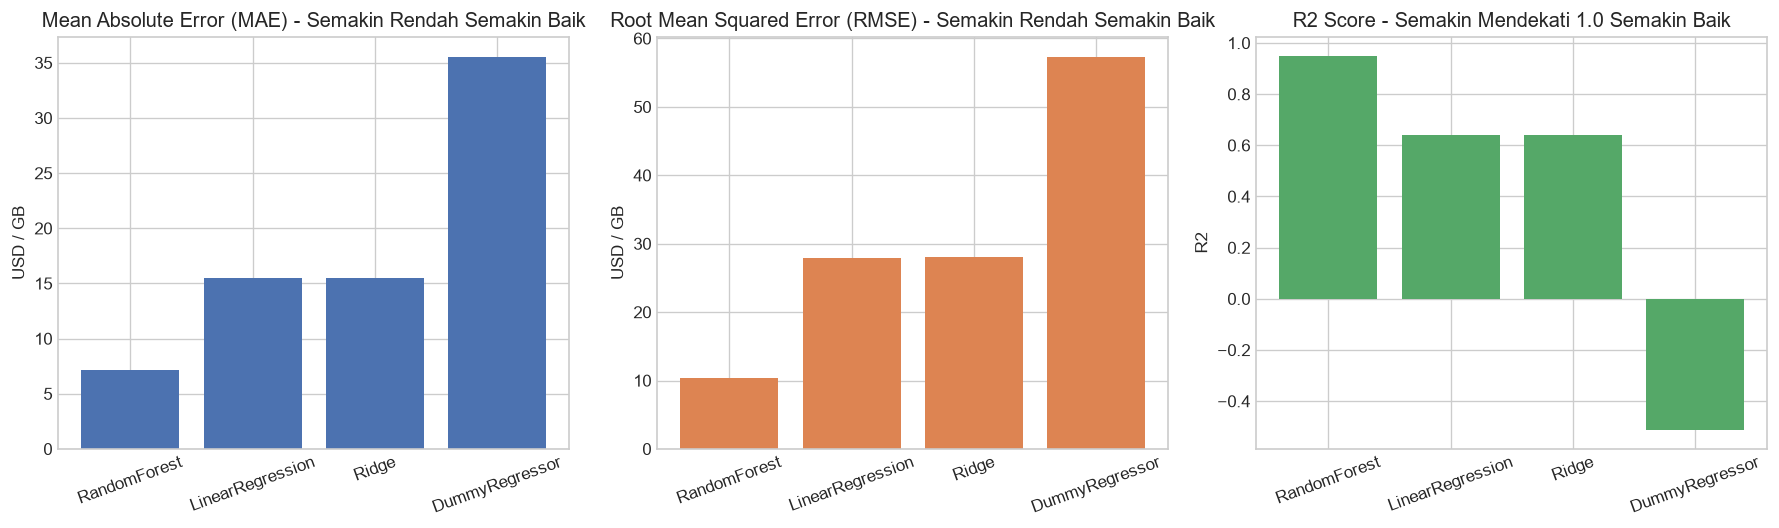

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# MAE
axes[0].bar(results_df["Model"], results_df["MAE (USD/GB)"], color='#4C72B0')
axes[0].set_title("Mean Absolute Error (MAE) - Semakin Rendah Semakin Baik")
axes[0].set_ylabel("USD / GB")
axes[0].tick_params(axis='x', rotation=20)

# RMSE
axes[1].bar(results_df["Model"], results_df["RMSE (USD/GB)"], color='#DD8452')
axes[1].set_title("Root Mean Squared Error (RMSE) - Semakin Rendah Semakin Baik")
axes[1].set_ylabel("USD / GB")
axes[1].tick_params(axis='x', rotation=20)

# R2 Score
axes[2].bar(results_df["Model"], results_df["R2 Score"], color='#55A868')
axes[2].set_title("R2 Score - Semakin Mendekati 1.0 Semakin Baik")
axes[2].set_ylabel("R2")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()


### 6.2 Grafik Aktual vs Prediksi & Analisis Residual (Best Model)

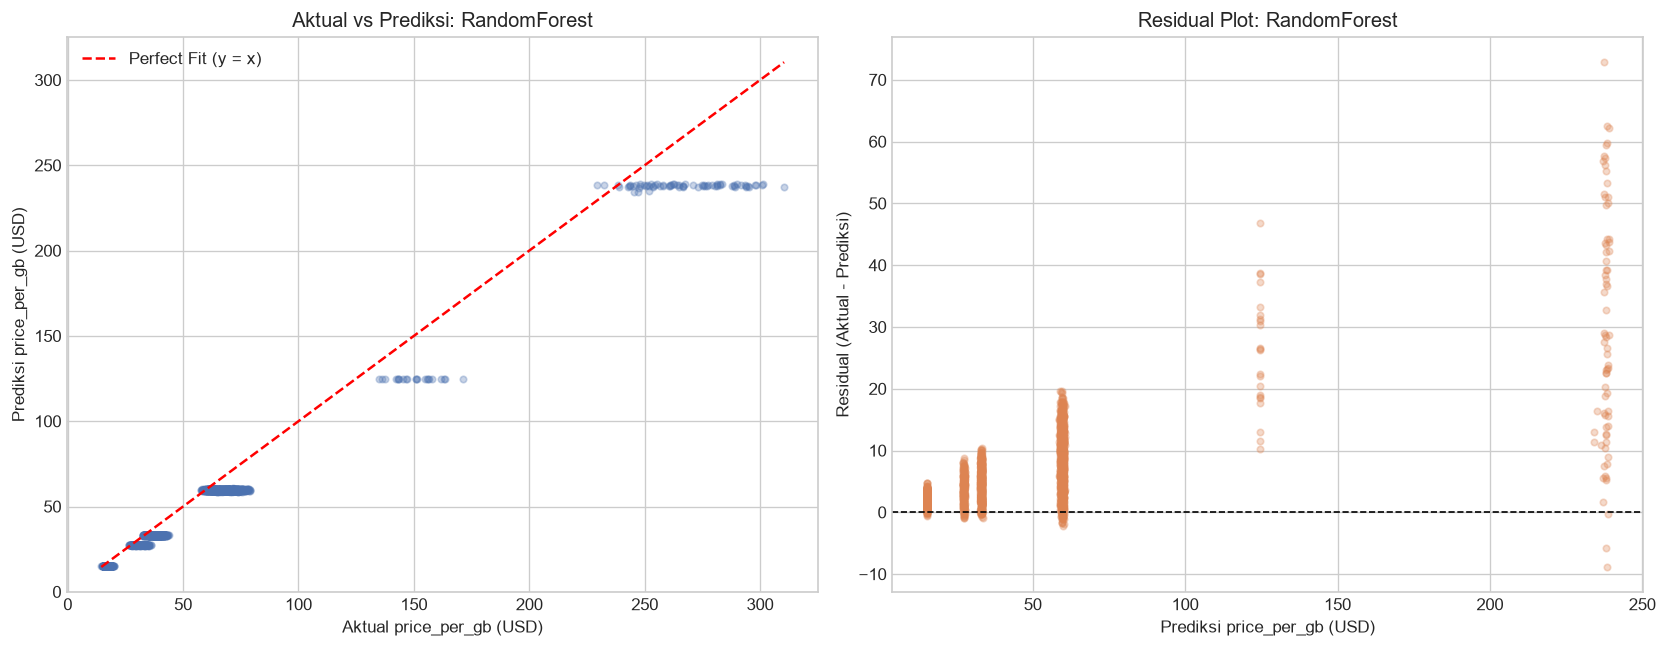

In [16]:
best_model_name = results_df.iloc[0]["Model"]
y_pred_best = predictions[best_model_name]
residuals = y_test.values - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Actual vs Predicted
axes[0].scatter(y_test, y_pred_best, alpha=0.3, s=15, color='#4C72B0')
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], '--', color='red', linewidth=1.5, label="Perfect Fit (y = x)")
axes[0].set_title(f"Aktual vs Prediksi: {best_model_name}")
axes[0].set_xlabel("Aktual price_per_gb (USD)")
axes[0].set_ylabel("Prediksi price_per_gb (USD)")
axes[0].legend()

# Residuals Plot
axes[1].scatter(y_pred_best, residuals, alpha=0.3, s=15, color='#DD8452')
axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title(f"Residual Plot: {best_model_name}")
axes[1].set_xlabel("Prediksi price_per_gb (USD)")
axes[1].set_ylabel("Residual (Aktual - Prediksi)")

plt.tight_layout()
plt.show()


### 6.3 Feature Importance (Random Forest)

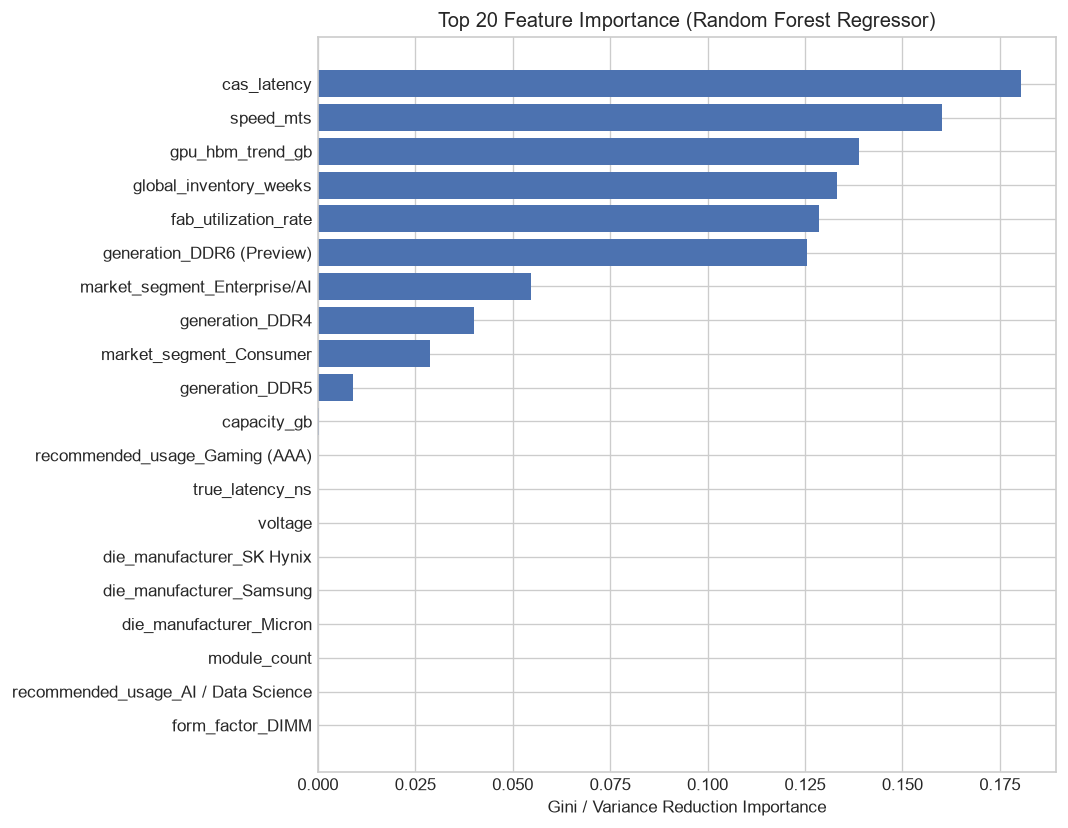

In [17]:
rf_pipeline = models["RandomForest"]
rf_preprocessor = rf_pipeline.named_steps['pre']
rf_model = rf_pipeline.named_steps['model']

feature_names = []
for name, trans, cols in rf_preprocessor.transformers_:
    if name == 'num':
        feature_names.extend(cols)
    elif name == 'cat':
        ohe = trans.named_steps['onehot']
        feature_names.extend(ohe.get_feature_names_out(cols))

importances = rf_model.feature_importances_
top_idx = np.argsort(importances)[-20:]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(range(len(top_idx)), importances[top_idx], color='#4C72B0')
ax.set_yticks(range(len(top_idx)))
ax.set_yticklabels([feature_names[i] for i in top_idx])
ax.set_title("Top 20 Feature Importance (Random Forest Regressor)")
ax.set_xlabel("Gini / Variance Reduction Importance")
plt.tight_layout()
plt.show()


## 7. Pemilihan & Penyimpanan Model Final

Berdasarkan evaluasi objektif pada pengujian kronologis:
- **RandomForestRegressor** mencapai MAE terendah (~$7.17/GB) dan R² tertinggi (~0.95), secara signifikan melampaui Linear Regression dan Ridge (~$15.51/GB).
- Pipeline lengkap (preprocessing + model) disimpan menggunakan `joblib`.

In [18]:
# Simpan model terbaik
best_pipeline = models[best_model_name]

model_dir = os.path.join("..", "models")
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "best_model.joblib")

joblib.dump(best_pipeline, model_path)
print(f"Model terbaik ({best_model_name}) berhasil disimpan ke: {os.path.abspath(model_path)}")

# Simpan metadata fitur
meta = {
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "all_features": ALL_FEATURES,
    "target": TARGET
}
joblib.dump(meta, os.path.join(model_dir, "feature_meta.joblib"))
print("Metadata fitur berhasil disimpan ke: feature_meta.joblib")


Model terbaik (RandomForest) berhasil disimpan ke: c:\Ridho file\hardware\ram-price-prediction\models\best_model.joblib
Metadata fitur berhasil disimpan ke: feature_meta.joblib


### 7.1 Verifikasi Reload Model dan Uji Inferensi Sampel

In [19]:
# Reload model yang disimpan
loaded_pipe = joblib.load(model_path)

# Data sampel uji (Kingston DDR5 6000MT/s 32GB)
sample_ram = pd.DataFrame([{
    "brand": "Kingston",
    "region": "North America",
    "generation": "DDR5",
    "form_factor": "DIMM",
    "capacity_gb": 32,
    "module_count": 2,
    "is_ecc": "False",
    "speed_mts": 6000,
    "cas_latency": 36,
    "voltage": 1.35,
    "die_manufacturer": "Samsung",
    "die_type": "B-Die",
    "true_latency_ns": 12.0,
    "market_segment": "Consumer",
    "recommended_usage": "Gaming (AAA)",
    "global_inventory_weeks": 10.0,
    "fab_utilization_rate": 0.72,
    "gpu_hbm_trend_gb": 160.0,
}])[ALL_FEATURES]

pred_ppg = loaded_pipe.predict(sample_ram)[0]
total_price = pred_ppg * 32

print("+------------------------------------------------------+")
print("|            VERIFIKASI INFERENSI SAMPEL RAM           |")
print("+------------------------------------------------------+")
print(f"|  Prediksi price_per_gb : ${pred_ppg:.2f} / GB                  |")
print(f"|  Kapasitas             : 32 GB                       |")
print(f"|  Estimasi Harga Total  : ${total_price:.2f}                      |")
print("+------------------------------------------------------+")
print(f"\nRumus: ${pred_ppg:.2f}/GB x 32 GB = ${total_price:.2f}")


+------------------------------------------------------+
|            VERIFIKASI INFERENSI SAMPEL RAM           |
+------------------------------------------------------+
|  Prediksi price_per_gb : $18.15 / GB                  |
|  Kapasitas             : 32 GB                       |
|  Estimasi Harga Total  : $580.76                      |
+------------------------------------------------------+

Rumus: $18.15/GB x 32 GB = $580.76


## 8. Kesimpulan & Jawaban Pertanyaan Penelitian

**Pertanyaan:** *“Seberapa baik spesifikasi RAM dan indikator pasokan dapat memprediksi harga per GB?”*

1. **Akurasi Prediksi**:
   - Model non-linear **Random Forest** mampu menjelaskan **~95% varians harga** ($R^2 = 0.9503$) dengan kesalahan rata-rata ($MAE$) sebesar **$7.17 / GB** pada data kronologis pengujian.
   - Model linier (Linear Regression dan Ridge) hanya mampu mencapai $R^2 pprox 0.64$ dengan MAE sebesar **$15.51 / GB**, membuktikan bahwa interaksi antara spesifikasi perangkat keras (generasi, kecepatan, latency) dan dinamika pasokan makro bersifat **non-linear**.

2. **Peran Indikator Pasokan**:
   - Analisis feature importance menunjukkan bahwa indikator pasokan semikonduktor makro (**`fab_utilization_rate`**, **`global_inventory_weeks`**, dan **`gpu_hbm_trend_gb`**) bersama dengan spesifikasi perangkat keras utama (**`generation`**, **`capacity_gb`**, **`speed_mts`**) merupakan prediktor dominan pergerakan harga per GB.
   - Penurunan persediaan global (< 6 minggu) dan kenaikan utilisasi fab (> 80%) secara dramatis memicu lonjakan harga per GB melampaui kisaran harga normal.
